In [1]:
import matplotlib.pyplot as plt
import numpy as np
import random

Micrograd is a Scalar Valued Autograd Engine. So, it works on level of Individual Scalars like -4 and 2.<br>
We are taking Neural nets and breaking them down to these atoms of individual Scalars, all the littel pluses and times and all of this is excessive.<br>

It's done for Pedagogical (learning) reasons, so that you avoid having to deal with n-dimensional tensors that you deal with in Modern Deep Neural Network Libraries

Derivateies in Python will fail if dx is made 0.00000000001 or something very small similar to this.<br>
This is because of Floating Point Arithmetic in Computers breaks down as we represent them using finite memory.

In [2]:
class Value:
  def __init__(self, data, _children=(), _op='', label = ''):
    self.data = data
    self.grad = 0
    self._backward = lambda: None
    self._prev = set(_children)
    self._op = _op
    self.label = label

  def __repr__(self):
    return f"Value(data={self.data})"

  def __add__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self, other), '+')

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward

    return out
  def __radd__(self, other): # other + self
    return self + other

  def __mul__(self, other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data * other.data, (self, other), '*')

    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward

    return out

  def __rmul__(self, other): # other * self
    return self * other

  def __pow__(self, other):
    assert isinstance(other, (int, float)), "only supporting int/float powers for now"
    out = Value(self.data**other, (self,), f'**{other}')

    def _backward():
        self.grad += (other * self.data**(other-1)) * out.grad
    out._backward = _backward

    return out


  def __truediv__(self, other): # self / other
    return self * other**-1

  def __neg__(self): # -self
    return self * -1

  def __sub__(self, other): # self - other
    return self + (-other)

  def __rsub__(self, other): # other - self
    return other + (-self)

  def tanh(self):
    x = self.data
    t = (np.exp(2*x) - 1) / (np.exp(2*x) + 1)
    out = Value(t, (self,), 'tanh')

    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward

    return out

  def exp(self):
    x = self.data
    out = Value(np.exp(x), (self,), 'exp')

    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward

    return out

  def backward(self):
    topo = []
    visited = set()
    def build_topo(v):
        if v not in visited:
            visited.add(v)
            for child in v._prev:
                build_topo(child)
            topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
        node._backward()

    return None

In [3]:
from graphviz import Digraph

def trace(root):
    # builds a set of all nodes and edges in a graph
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        # for any value in the graph, create a rectangular ('record') node for it
        dot.node(name=uid, label= "{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            # if this value is a result of some operation, create an op node for it
            dot.node(name=uid + n._op, label=n._op)
            # and connect this node to it
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        # connect n1 to the op node of n2
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

In [4]:
a = Value(4.0, label='a')
b = 3
c = a**b

In [5]:
b-a

Value(data=-1.0)

In [6]:
print(c.data)
print(c.grad)
print(c._backward)
print(c._prev)
print(c._op)
print(c.label)

64.0
0
<function Value.__pow__.<locals>._backward at 0x726834c60040>
{Value(data=4.0)}
**3



In [7]:
c.backward()

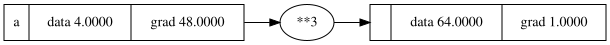

In [9]:
draw_dot(c)

When we have no _children, we are missing the connective tissue of this graph. We want to know and keep pointers about what values produce what other values.<br>
So he created an empty tuple called _children. And a different variable within the class called _prev, which will be the set of children.<br>

For new values, it does not have any history/children, but when we are creating new values through addition or multiplication, we can assign the operands to this _children, so we can keep track of what operands caused this result<br>

We now know what operands created this value, but we don't know what operator created this value, so we add _op.


### Backpropagation is the recusrsive application of the chain rule, backwards through the computation graph.

Once the gradients are calculated, now we want to nudge our inputs like a and b to make L go up.

If we want L to go up we want to go in the direction of the gradient.

We have to nudge each value in the direction of the gradient, to make the final variable L, go up.
We should do this nudging for the independent variables.

Activation Functions will squash the input to a particular range. <br>
For example, tanh, will squish the output between -1 and +1

In [10]:
a = Value(2.0, label='a')
a + 2

Value(data=4.0)

In [12]:
#inputs x1, x2
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')
#weights w1, w2
w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
#bias b
b = Value(6.8813735870195432, label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1 * w1; x1w1.label = 'x1w1'
x2w2 = x2 * w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2.label = 'x1w1x2w2'
n = x1w1x2w2 + b; n.label = 'n'
#---
e = (2*n).exp() ; e.label = 'e'
o = (e - 1) / (e + 1)
#---
o.label = 'o'
o.backward()

We need to find what is the derivatinve of o wrt inputs. In a neural network setting, we typically care about the derivatives of o wrt weights, w2 and w1

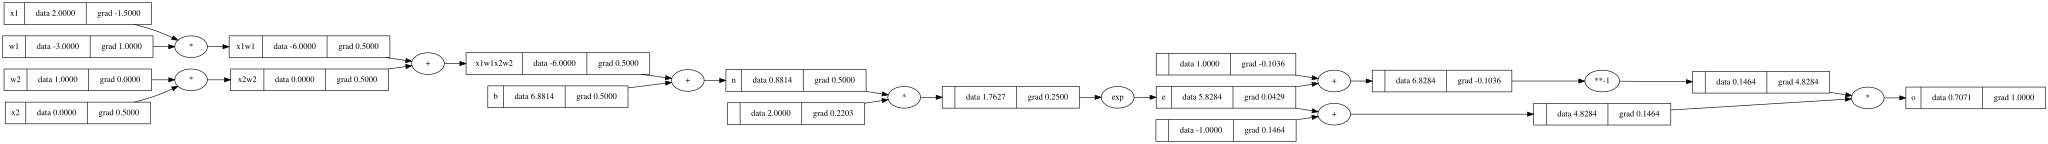

In [13]:
draw_dot(o)

Topological Sort means laying out the graph in such a way that all the edges go from left to right.

In [14]:
import torch

In [15]:
random.uniform(-1,1)

-0.2760282097212967

In [16]:

x1 = torch.Tensor([2.0]).double()   ; x1.requires_grad = True
x2 = torch.Tensor([0.0]).double()   ; x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double()  ; w1.requires_grad = True
w2 = torch.Tensor([1.0]).double()   ; w2.requires_grad = True
b = torch.Tensor([6.8813735870195432]).double()  ; b.requires_grad = True
n = x1*w1 + x2*w2 + b
o = torch.tanh(n)

print(o.data)
print(o.data.item())
o.backward()

print('---')
print('x2', x2.grad.item())
print('w2', w2.grad.item())
print('x1', x1.grad.item())
print('w1', w1.grad.item())


tensor([0.7071], dtype=torch.float64)
0.7071066904050358
---
x2 0.5000001283844369
w2 0.0
x1 -1.5000003851533106
w1 1.0000002567688737


In [ ]:
class Neuron:

  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # Sum takes a optional parameter start. it is usually 0.0, but here we give it value of self.b
    out = act.tanh()
    return out

x = [2.0, 3.0]
n = Neuron(2)
n(x)

Value(data=-0.9360243934682871)

In [26]:
# A Layer of neurons is a set of neurons evaluated independently.
class Layer:
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

x = [2.0, 3.0]
n = Layer(2,3)
n(x)

[Value(data=-0.5242486643091555),
 Value(data=0.9493404057771268),
 Value(data=0.7211136001992301)]

In [27]:
# Instead of taking asingle nout,we take a list of nouts. 
# This list defines the size of each Layer in our MLP.
class MLP:
  def __init__(self, nin, nouts: list[int]):
    sz = [nin] + nouts  #Put them all together
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]  # Iterate over consecutive pairs of sizes and create layer objects for them. THen in the call function we call these layers sequentially.

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.neurons]

x = [2.0, 3.0, 4.0]
n = MLP(3, [4, 4, 1])
n(x)

Value(data=-0.5339030777636815)

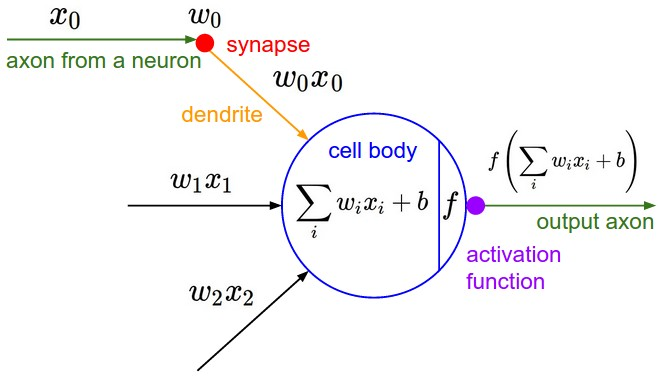

In [ ]:
# This just initializes the neuron with weights and biases
# The printed output values are initila values of w1, w2, w3, w4 and b
# Neuron(4) means a neuron with 4 inputs. So it will have 4 inputs, 4 weights and 1 bias
myneuron = Neuron(4)
print(myneuron.w)
print(myneuron.b)

# In previous step, I created a neuron with 4 weights, so I have to give it input of 4 variables.
myinput = [1.0, 2.0, 3.0, 4.0]
print(myinput)

[Value(data=-0.5609513752885362), Value(data=-0.8777147933270151), Value(data=0.12399323898078651), Value(data=0.5586238124415541)]
Value(data=0.04998445682432151)
[1.0, 2.0, 3.0, 4.0]


### Neuron execution step

Once my input and initialized weights are ready, I just call the neuron object.  
I can call this object as function itself because I defined a method inside the class called `__call__`.  
This call performs Σ(wᵢ * xᵢ) + b and then applies the activation function.  
`w_i` values are objects of class `Value`, so `tanh()` can be applied to the result directly.


In [ ]:
myneuron(myinput)

Value(data=0.32754744026486265)

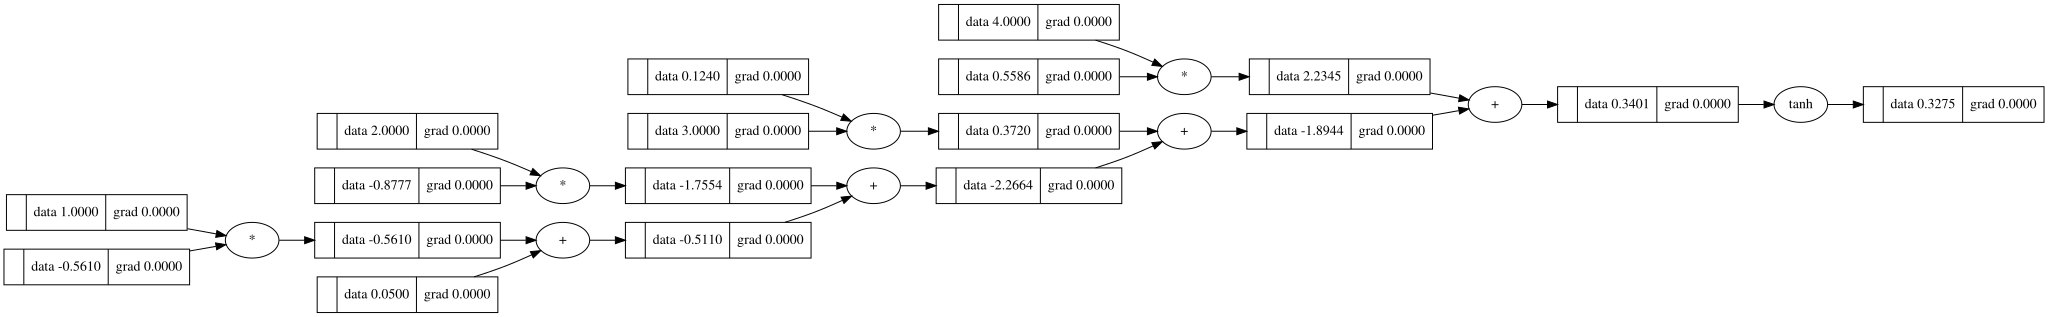

In [ ]:
draw_dot(myneuron(myinput))

In [ ]:
x = [2.0, 3.0]
n = Neuron(2)
n(x)

Value(data=-0.9375112636536506)

### Layer of Neurons


In [28]:
Layer1 = Layer(3, 4)

In [29]:
Layer1.neurons
# This will print 4 neurons because the second parameter is the actual number of neurons in that layer.
# The first parameter just gives the information about how many neurons are present in the previous layer.

In [30]:
x = [3.0, -2.0]
l = Layer(4,3)
l(x)

[Value(data=0.9717526454777982),
 Value(data=0.8746234155886946),
 Value(data=-0.9968152849121006)]

In [31]:
print([n(x) for n in l.neurons])

[Value(data=0.9717526454777982), Value(data=0.8746234155886946), Value(data=-0.9968152849121006)]


In [ ]:
# Where did the 4 of the Layer(4,3) go?

- `self.w` has length **4** (because `nin = 4`)
- `x` has length **2**

In Python, `zip(self.w, x)` stops at the **shorter** iterable,  
so it only produces **2 pairs**:

- `(w_0, 3.0)`
- `(w_1, -2.0)`

As a result, the neuron computes:

$$
w_0 \cdot 3.0 + w_1 \cdot (-2.0) + b
$$

and **silently ignores** the remaining weights:

- $w_2$
- $w_3$

This happens because `zip` does **not** raise an error when lengths differ — it simply truncates to the shortest input.


If you want it to behave like a **real 4-input neuron**, you should explicitly check that the input length matches the number of weights:

```python
def __call__(self, x):
    if len(x) != len(self.w):
        raise ValueError(
            f"Expected {len(self.w)} inputs, got {len(x)}"
        )



*   Layer expects 4 inputs ❌ (not checked)
*   zip truncates 4 weights to 2 inputs ✅
*   neuron computes with 2 inputs instead of 4 ✅
*   result returned without complaint ✅


In [109]:
class Neuron:

  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self, x):
    # w * x + b
    act = sum((wi*xi for wi, xi in zip(self.w, x)), self.b) # Sum takes a optional parameter start. it is usually 0.0, but here we give it value of self.b
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

  # A Layer of neurons is a set of neurons evaluated independently.
class Layer:
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self, x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
      return [p for neuron in self.neurons for p in neuron.parameters()]

# Instead of taking asingle nout,we take a list of nouts. 
# This list defines the size of each Layer in our MLP.
class MLP:
  def __init__(self, nin, nouts: list[int]):
    sz = [nin] + nouts  #Put them all together
    self.layers = [Layer(sz[i], sz[i+1]) for i in range(len(nouts))]  # Iterate over consecutive pairs of sizes and create layer objects for them. THen in the call function we call these layers sequentially.

  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]

In [110]:
# Dummy example
x = [2.0, 3.0, -1.0]
mlp = MLP(3, [4, 4, 1])
mlp(x)

Value(data=0.6595662537933203)

In [ ]:
draw_dot(mlp(x))

In [112]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0] #desired targets

mlp = MLP(3, [4, 4, 1]) # Note- Karpathy uses n as the name of the neural network layer. I am using lowercase 'mlp' as the name

ypred = [mlp(x) for x in xs]
ypred

[Value(data=-0.2423052348232999),
 Value(data=-0.6995032581861234),
 Value(data=-0.26014747815451306),
 Value(data=-0.22024753643079129)]

We want first to be 1.0, <br>
2nd to be -1.0, <br>
3rd to be -1.0, <br>
4th to be 1.0 <br>

How do we train the neural net to better predict these desired targets?

The trick used in Deep Learning to achieve this is to calculate a single number that somehow measures the total performance of your neural net. We call this single number the **Loss.**<br>
We do the manual calculation of Loss below

In [96]:
# Let's implement the mean squared error loss.
loss = [(ygt - yout)**2 for ygt, yout in zip(ys, ypred)]
loss

[Value(data=0.5366220732398806),
 Value(data=3.240287657914555),
 Value(data=0.16353698348870066),
 Value(data=0.6121878935276912)]

The above is the loss for each example. THe final loss will be the sum of all these losses.

In [113]:
loss = sum([(ygt - yout)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=3.6700063925566715)

Now we want to minimize the loss

In [114]:
# Before loss.backward(). For all weights ".grad" will give value = 0.0. Make sure to run this just after MLP creation cell. If you run this more than once, the first cell will no longer have grad = 0.0 (We dont have optimizer.zero_grad yet unfortunately)
print(mlp.layers[0].neurons[0].w[0])
print(mlp.layers[0].neurons[0].w[0].grad)

loss.backward()

# After loss.backward(). 
# #Now, w[0].grad has a weight that was calculated via backpropagation.
print(mlp.layers[0].neurons[0].w[0])
print(mlp.layers[0].neurons[0].w[0].grad)


Value(data=-0.7106107189744773)
0
Value(data=-0.7106107189744773)
0.1754806361082013


The loss backpropagates through all the four forward passes, all the way to the parameters of the weights, which are the input to the neural net.( present in the very first layer of the draw_dot diagram) <br>

The x's are also inputs to the neural net <br>

------------------------------------------------------------------------
The gradients on the input data are not that important to us and that's because the input data is not changable. <br>

It's a "Given" in the problem and its fixed. We can't nudge these values even though we do have gradients for it.

---------------------------------------------------------------
Some of the gradients in the draw_dot diagram will be for the neural network parameters, the w's and the b's.<br>
Those are things we ofcourse want to change.


------------
So now we're going to want some convenience code to gather up all of the parameters of the neural net so that we can operate on all of them simultaneously, and every one of them we will nudge a tiny amount based on the gradient information so let's collect the parameters of the neural net all in one array.<br>

So let's create a parameters of self that just returns celta w which is a list concatenated with a list of self.b <br>

So this will just return a list.

In [117]:
len(mlp.parameters())

41

In [118]:
# Gradient Descent Step
for p in mlp.parameters():
    p.data = p.data - 0.01*p.grad

In [119]:
print(mlp.layers[0].neurons[0].w[0])
print(mlp.layers[0].neurons[0].w[0].grad)

Value(data=-0.7123655253355593)
0.1754806361082013


In [ ]:
# The Gradeint Descent loop

# 1.Forward Pass and Loss Prediction
# 2.loss.backwards() - calcualtes the gradients
# 3.Update, ie optimizer.step()

In [177]:
# 1.Forward Pass and Loss Prediction
ypred = [mlp(x) for x in xs]
loss = sum([(ygt - yout)**2 for ygt, yout in zip(ys, ypred)])
loss

Value(data=0.0022524129611175632)

In [178]:
# 2.loss.backwards() - calcualtes the gradients
loss.backward()

In [179]:
# 3.Update, ie optimizer.step()
for p in mlp.parameters():
    p.data = p.data - 0.01*p.grad

In [180]:
ypred

[Value(data=0.9912390423601638),
 Value(data=-0.9674125010718522),
 Value(data=-0.9671075596463797),
 Value(data=0.9943607745618697)]

In [214]:
xs = [
    [2.0, 3.0, -1.0],
    [3.0, -1.0, 0.5],
    [0.5, 1.0, 1.0],
    [1.0, 1.0, -1.0]
]

ys = [1.0, -1.0, -1.0, 1.0] #desired targets

mlp = MLP(3, [4, 4, 1])

for k in range(25):
    # 1.Forward Pass and Loss Prediction
    ypred = [mlp(x) for x in xs]
    loss = sum([(ygt - yout)**2 for ygt, yout in zip(ys, ypred)])

    # 1b. Zero grad it
    for p in mlp.parameters():
        p.grad = 0.0

    # 2.loss.backwards() - calcualtes the gradients
    loss.backward()

    # 3.Update, ie optimizer.step()
    for p in mlp.parameters():
        p.data = p.data - 0.05*p.grad

    print(k, loss.data)

0 3.135499482970502
1 0.9023180449265384
2 0.4689073921445017
3 0.30671312500737363
4 0.23116092972760902
5 0.18389545818856276
6 0.15194773536577302
7 0.12906263394793152
8 0.11192810965702857
9 0.0986506673511952
10 0.08807741470257946
11 0.07946927951891468
12 0.07233192650294445
13 0.06632280737539868
14 0.06119736459031676
15 0.05677649856125383
16 0.05292613791766941
17 0.04954398457526851
18 0.04655066548352912
19 0.04388367631814358
20 0.041493143282696945
21 0.03933879808866651
22 0.03738778030272946
23 0.03561301511295223
24 0.033991998438068174
